# Hands-on · one HCC core, three modalities
**MERIT (CNRS) workshop · spatial multimodal integration**

Same FFPE section, three instruments: **H&E**, **Xenium Prime 5K** (5,001 genes, 8,290 cells) and **COMET** (DAPI + 15 proteins).
Two packages, two levels:

* **multispace** (cell level): one SpatialData object with a fixed data contract, image registration, cell typing, spatial statistics.
  multispace is our in-house package (not yet published). It grew out of **MOSAIK** (Baptista et al., github.com/anthbapt/MOSAIK)
  and contains MOSAIK's resegmentation code.
* **spatiomic** (pixel level): self-organising map + Leiden clustering of the COMET pixels, with no segmentation.

| # | Task |
|---|---|
| 1 | Load the object, look at the three layers |
| 2 | Registration and segmentation QC (multispace) |
| 3 | Pixel clusters on a COMET crop (spatiomic) |
| 4 | Pixels → cells, then a joint embedding vs RNA only |
| 4b | One multilayer network on the same cells (optional) |
| 5 | In pairs: RNA vs protein  |
| 5b | Cell typing with RNA + protein markers (optional) |
| 5c | Who sits next to whom: neighbourhood enrichment |
| 6 | Tumour vs non-tumour: core01 vs core02 (precomputed) |

The heavy steps (registration of the full H&E, cell typing, spatiomic on the whole core) were run beforehand with
`prepare_core01.py` and `prepare_core02.py`; their outputs are in `prepared/`. Resegmentation is not run in this
session (no Xenium morphology image ships with this dataset, and it needs a GPU): section 2 shows results obtained beforehand. Everything in this notebook runs on a laptop CPU in a few seconds per cell.

**Setup** (repository root): `conda env create -f environment.yml && conda activate merit` (Python 3.12; multispace is
installed from `wheels/`), then `python handson/download_data.py` for the `prepared/` folder (~560 MB).

In [1]:
# --- CONFIG -------------------------------------------------------------------
from pathlib import Path
PREP = Path("prepared")            # folder from prepare_core01.py: core01_ms.zarr + precomputed results
ZARR = PREP / "core01_ms.zarr"
# A 1000 × 1000 px window (COMET pixels, ~280 µm): tumour nests, stroma and a lymphoid aggregate
CROP = dict(y0=2000, y1=3000, x0=1800, x1=2800)
RUN_REGISTRATION = False           # True: re-run multispace's H&E registration (~1-3 min)

In [2]:
import warnings, json; warnings.filterwarnings("ignore")
from IPython.display import Image, display
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import scanpy as sc, spatialdata as sd, spatialdata_plot  # noqa: F401 (adds .pl)
import multispace as ms
import spatiomic as so
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from workshop_hcc import *   # helpers for this hands-on (pixel clustering, pixels → cells, metrics)
sc.settings.verbosity = 0

## 1 · Load the object and look at the three layers

In [3]:
sdata = sd.read_zarr(ZARR)
sdata

SpatialData object, with associated Zarr store: /Users/k2481276/Documents/MERIT-CNRS-workshop-Nov-2026/prepared/core01_ms.zarr
├── Images
│     ├── 'he': DataArray[cyx] (3, 5735, 5678)
│     ├── 'if': DataArray[cyx] (16, 4088, 4116)
│     └── 'morphology_focus': DataArray[cyx] (1, 4088, 4116)
├── Points
│     └── 'transcripts': DataFrame with shape: (7241612, 13) (2D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (8290, 1) (2D shapes)
│     ├── 'comet_cell_masks': GeoDataFrame shape: (6418, 1) (2D shapes)
│     ├── 'comet_nucleus_masks': GeoDataFrame shape: (6418, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (8037, 1) (2D shapes)
└── Tables
      ├── 'table': AnnData (8290, 5001)
      └── 'table_comet': AnnData (6418, 16)
with coordinate systems:
    ▸ 'global', with elements:
        he (Images), if (Images), morphology_focus (Images), transcripts (Points), cell_boundaries (Shapes), comet_cell_masks (Shapes), comet_nucleus_masks (Shapes), nu

Everything sits in one coordinate system, `global` = the COMET pixel grid (1 px ≈ 0.28 µm).
The Xenium elements and the H&E reach it through an affine transform. The table follows the **multispace contract**:
RNA counts in `X`, the 16 COMET intensities in `obsm['protein']`, cell types in `obs['cell_type']`.

**Cell types** come from the multispace *marker strategy* (`annotate_clusters_by_markers`): Leiden clusters on the RNA
(resolution 2.0, 23 clusters), a signed score per cluster for each cell type (positive minus negative markers,
`LIVER_MARKERS_SIGNED` in `workshop_hcc.py`), and one label per cluster. `cell_type_confidence` is the cluster's
winner / runner-up score ratio.

> **Caveat on the markers.** The Xenium Prime 5K panel lacks several textbook liver markers: **ALB, KRT19, COL1A1, PTPRC**
> (and GPC3, AFP, KRT7, APOA1, CYP3A4). We use substitutes: APOB, AHSG, CPS1, ARG1 and HNF4A for hepatocytes; EPCAM, SOX9 and
> CFTR for cholangiocytes; PDGFRB, RGS5 and COL4A1 for stroma; immune lineage genes instead of PTPRC. **HCC tumour vs normal
> hepatocyte** rests on oncofetal genes (IGF2, DLK1, PEG10, H19) against CPS1/ARG1, and the separation is weak (winner /
> runner-up ratio ≈ 1.1 for most hepatocyte-like clusters). Treat "HCC tumour" and "Hepatocyte" as one hepatocyte-lineage
> compartment unless the protein layer (HepPar1, CK8) or the H&E supports the split. Good enough for this workshop, not for a paper.
> Section 5b adds the protein markers to the same strategy.

In [4]:
from spatialdata.transformations import get_transformation
for name in ["if", "he", "cell_boundaries", "transcripts"]:
    el = sdata[name]
    print(f"{name:16s}", {cs: type(t).__name__ for cs, t in get_transformation(el, get_all=True).items()})
t = sdata.tables["table"]
print(t)
pd.concat([t.obs["cell_type"].value_counts().rename("cells"),
           t.obs.groupby("cell_type", observed=True)[["CD20_-_TRITC_positive", "CD45_-_TRITC_positive", "CK8_-_TRITC_positive"]]
            .mean().round(2).add_prefix("protein+ ")], axis=1)   # does the protein agree with the RNA-based labels?

if               {'global': 'Identity'}
he               {'he': 'Identity', 'he_reference': 'Affine', 'global': 'Affine'}
cell_boundaries  {'global': 'Affine'}
transcripts      {'global': 'Affine'}
AnnData object with n_obs × n_vars = 8290 × 5001
    obs: 'label', 'cell_id', 'centroid_x', 'centroid_y', 'area_px', 'DAPI_positive', 'CK8_-_TRITC_positive', 'VEGF_-_TRITC_positive', 'CD45RA_-_TRITC_positive', 'vimentin_-_TRITC_positive', 'E-Cadherin_-_TRITC_positive', 'CD1c_-_TRITC_positive', 'IL-10_-_TRITC_positive', 'podoplanin_-_FITC_positive', 'FXIIIa_-_FITC_positive', 'CD66_-_FITC_positive', 'CD20_-_TRITC_positive', 'alphaSMA_-_TRITC_positive', 'CD45_-_TRITC_positive', 'HepPar1_-_TRITC_positive', 'CD206_-_TRITC_positive', 'region', 'instance_id', 'cell_type', 'cell_type_cluster', 'cell_type_confidence', 'cell_type_score'
    uns: 'multispace_spatial', 'spatialdata_attrs'
    obsm: 'protein', 'spatial', 'X_umap'
    layers: 'counts', None (.X)


,cells,protein+ CD20_-_TRITC_positive,protein+ CD45_-_TRITC_positive,protein+ CK8_-_TRITC_positive
cell_type,,,,
HCC tumour,4353,0.00,0.00,0.96
T cell,1474,0.03,0.21,0.02
Fibroblast / stellate,1230,0.00,0.00,0.05
Macrophage,380,0.02,0.04,0.15
Hepatocyte,299,0.00,0.00,1.00
B cell,265,0.34,0.42,0.00
Endothelial,216,0.00,0.01,0.05
Dendritic cell,73,0.07,0.11,0.03


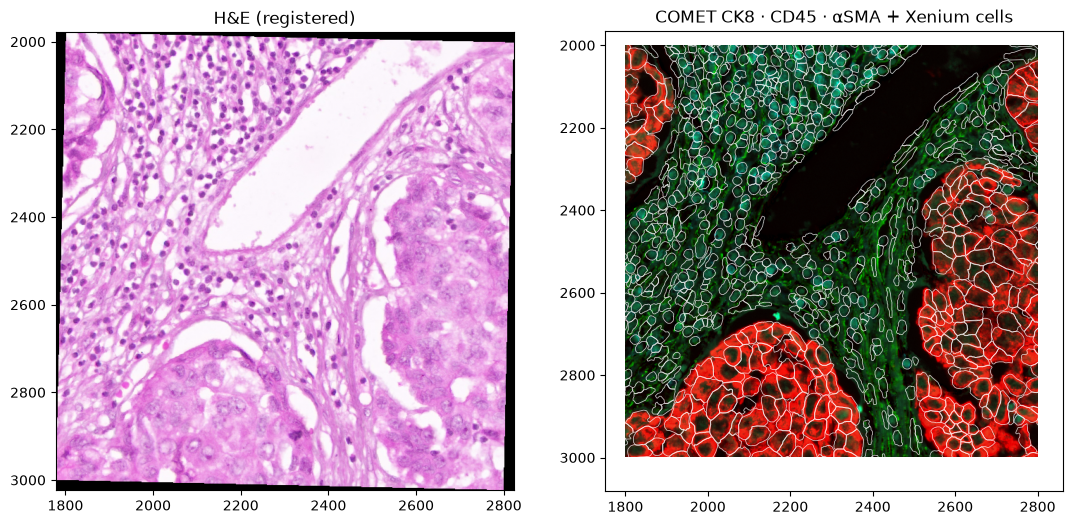

In [5]:
crop = sd.bounding_box_query(sdata, axes=("x", "y"), min_coordinate=[CROP["x0"], CROP["y0"]],
                             max_coordinate=[CROP["x1"], CROP["y1"]], target_coordinate_system="global")
fig, axs = plt.subplots(1, 2, figsize=(13, 6.5))
crop.pl.render_images("he").pl.show(coordinate_systems="global", ax=axs[0], title="H&E (registered)")
(crop.pl.render_images("if", channel=["CK8 - TRITC", "CD45 - TRITC", "αSMA - TRITC"], palette=["red", "cyan", "lime"])
     .pl.render_shapes("cell_boundaries", fill_alpha=0, outline_alpha=0.7, outline_color="white", outline_width=0.6)
     .pl.show(coordinate_systems="global", ax=axs[1], title="COMET CK8 · CD45 · αSMA + Xenium cells"))

**Question.** Do the Xenium cell outlines sit on the COMET nuclei? Where would you expect segmentation to struggle?

<details>
<summary><b>Answer</b> (click to reveal)</summary>

Yes, almost everywhere in this crop, because the registration is sub-pixel. Where they don’t match, it’s a segmentation problem, not a registration one.

Where to expect trouble in liver and HCC:

- Dense lymphoid aggregate: small, crowded nuclei get merged, or the expansions bleed into each other.
- Tightly packed tumour nests: boundaries between touching cells are guessed rather than seen.
- Hepatocytes: large and often binucleated, with faint membranes. They can be split into two cells, or under-sized by an expansion that is too small for them.
- Elongated stromal cells (αSMA, vimentin, endothelium): a round expansion doesn’t fit a spindle-shaped cell.
- Cells cut without their nucleus: in a 5 µm section, part of a cell can lie in the section while its nucleus doesn’t. A nucleus-based method misses those cells entirely.
- Areas with no nuclei at all (steatosis vacuoles, red cells, necrosis, folds and core edges): you’ll see false or missing cells there.

</details>

## 2 · Registration and segmentation QC with multispace 
The H&E was registered onto the COMET DAPI with `ms.register_image(sdata, "he", "morphology_focus", method="affine")`
(intensity-based, normalised mutual information). The dataset also ships a keypoint-based transform, kept as the coordinate
system `he_reference`: how far apart are the two?

In [6]:
if RUN_REGISTRATION:
    res = ms.register_image(sdata, "he", "morphology_focus", method="affine", max_side=1000)
    print(res.details.get("quality"))
reg = sdata.attrs["multispace"]["registration"]["he"]
print("method:", reg["method"], "| fixed:", reg["fixed"])
registration_error(sdata)   # displacement between the two transforms over the whole H&E, in COMET px and µm

method: affine | fixed: morphology_focus


,median_px,max_px,median_um,max_um
0,1.86144,4.070558,0.519794,1.136675


In [7]:
from shapely.affinity import affine_transform

def in_global(key):
    g = sdata.shapes[key]
    M = get_transformation(g, to_coordinate_system="global").to_affine_matrix(("x", "y"), ("x", "y"))
    return g.geometry.apply(lambda p: affine_transform(p, [M[0, 0], M[0, 1], M[1, 0], M[1, 1], M[0, 2], M[1, 2]]))

um2 = COMET_UM_PER_PX ** 2
seg = {name: in_global(key) for name, key in [("Xenium default", "cell_boundaries"), ("COMET InstaSeg", "comet_cell_masks")]}
pd.DataFrame({name: {"cells": len(g), "median area (µm²)": round(float(np.median(g.area)) * um2, 1)} for name, g in seg.items()}).T

,cells,median area (µm²)
Xenium default,8290.0,53.7
COMET InstaSeg,6418.0,64.1


**Question.** Same tissue, 8,290 vs 6,418 cells. Which segmentation would you trust for protein quantification, and why?

<details>
<summary><b>Answer</b> (click to reveal)</summary>

The COMET InstaSeg masks, because they were drawn on the same image the protein intensities come from.

- Same image, no transfer step. InstaSeg segmented the COMET image itself, so a mask and the signal it measures can’t be offset. Xenium outlines are drawn on another instrument’s DAPI and moved over with an affine fit. Here the fit is very good (8,286 of 8,290 cells matched, RMS ≈ 0.15 COMET px), so offset isn’t the main issue. The shape of the masks is.
- Boundaries follow the protein. InstaSeg uses the multiplex channels, so its edges follow membrane and cytoplasm markers (CD45, CD20, E-cadherin). Xenium’s default is mostly nucleus-based with an expansion around it. Its median area is smaller (53.7 vs 64.1 µm²), so it can cut off membrane signal, or pick up a neighbour’s where cells are packed.
- Neither count is “the truth”. The extra 1,900 Xenium cells could be real cells InstaSeg merged, for example in the dense lymphoid aggregate. They could also be over-split hepatocytes, or small expansion blobs in stroma. The way to find out is to look at the regions where the counts differ most, not to pick a number.
- The practical answer: use InstaSeg for protein-only analysis, but you still need one shared unit to fuse RNA and protein. That’s why the notebook uses the Xenium cells as the nodes and accepts the trade-off. Resegmentation (next section) and the pixel-level view (spatiomic) are the two ways out.

</details>

### Resegmentation: results shown, not run
multispace (from MOSAIK) resegments Xenium data in two steps: **Cellpose-SAM** on the morphology image gives a prior, then **Proseg**
moves the cell boundaries to fit the transcripts. This HCC dataset ships without the Xenium morphology image, and Proseg needs
~10 min per core on a GPU node, so here are the results on a breast-cancer Xenium core (METABRIC, MB-GU-1017) run on the HPC.

* Proseg keeps cells centred on their Cellpose prior (median shift 0.02–0.08 px) and assigns ~80% of transcripts.
* The validation caught a coordinate bug in the earlier code: transcripts were shifted by up to 34 px (7 µm), so in one cohort
  66% of transcripts had been counted in the wrong cell. Every run now checks its own registration (shift scan peaks at 0, 0).

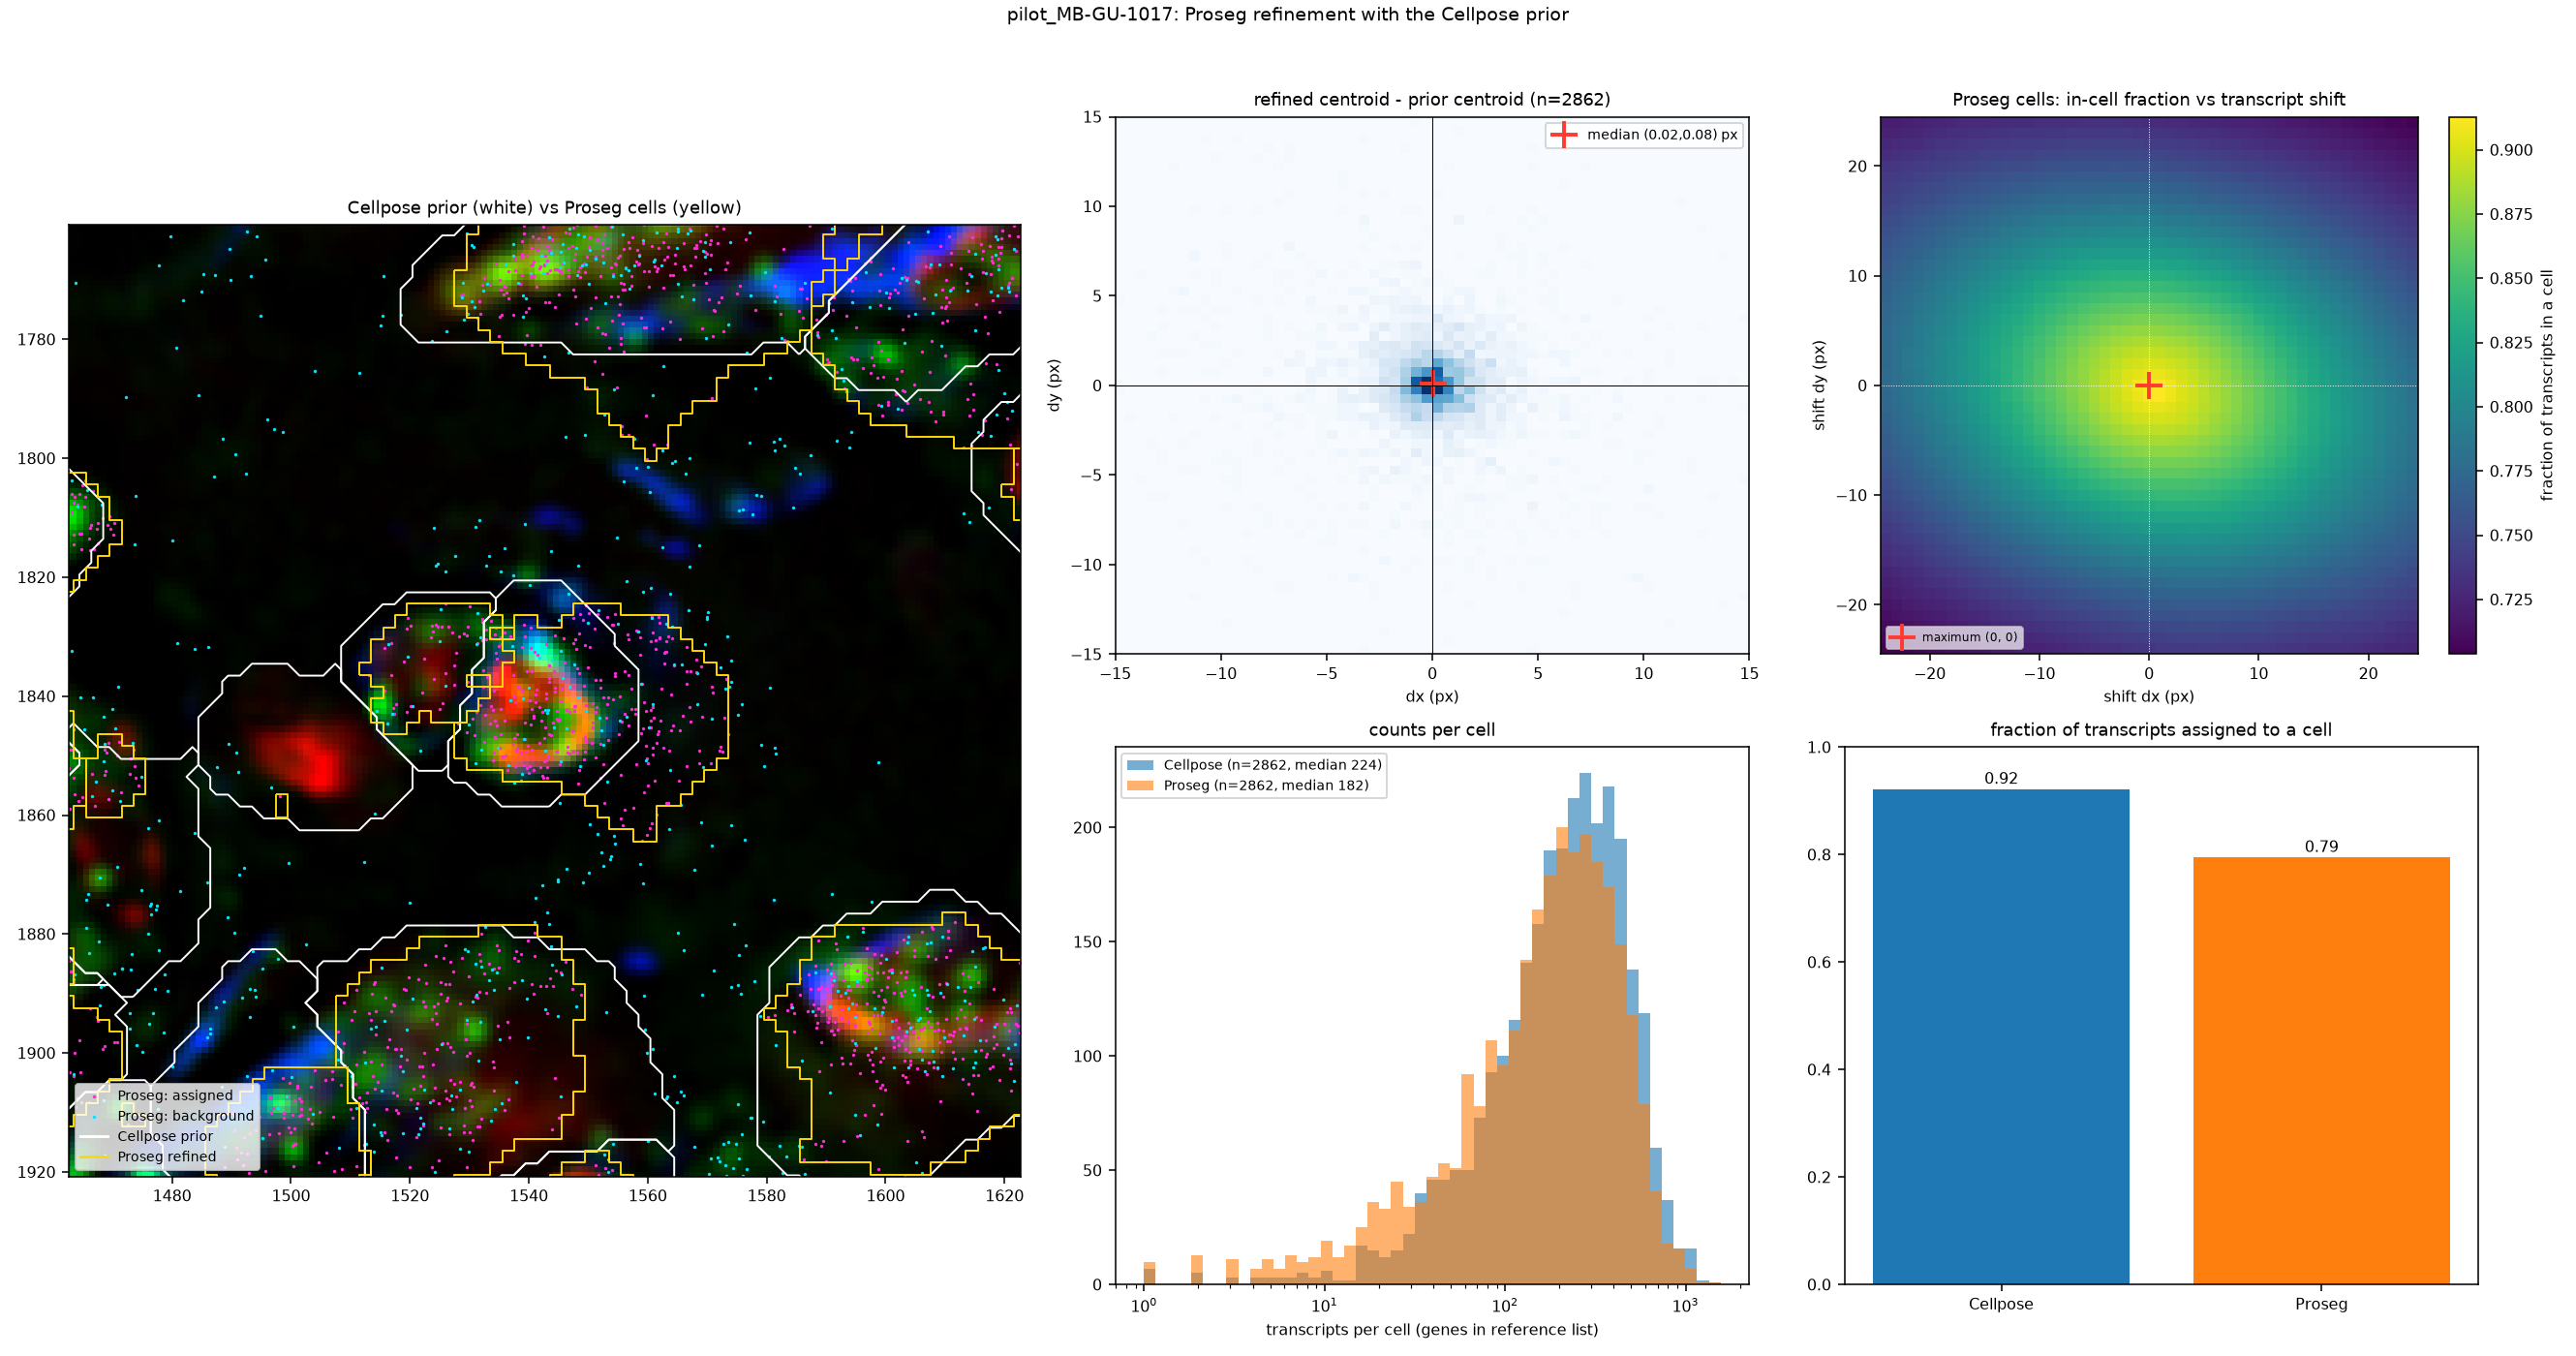

In [8]:
RESEG = PREP / "reseg_metabric"
display(Image(RESEG / "pilot_MB-GU-1017_5_proseg.png", width=1000))     # Cellpose prior vs Proseg cells, QC

**Question.** Proseg assigns fewer transcripts than Cellpose (79% vs 92%). Is that a problem? What happens to the rest?

<details>
<summary><b>Answer</b> (click to reveal)</summary>

Not necessarily. A higher fraction isn’t a better segmentation. The question is which transcripts were left out.

- Why Cellpose plus expansion gets 92%: its masks cover the tissue generously, so any transcript inside a mask is counted. That includes ambient RNA, transcripts that diffused away, and transcripts from neighbouring cells. The fraction looks good, but the profiles are mixed.
- What Proseg does instead: it fits a probabilistic model of where each cell’s transcripts are, with a background (noise) component. Transcripts that don’t fit any cell well are left unassigned. These include transcripts in the gaps between cells, low-confidence ones at the borders, and ones from cell fragments with no nucleus.
Where the other 21% goes: nowhere. They stay in the points layer of the SpatialData object, and only drop out of the cell × gene table. You can still use them in segmentation-free analyses (binning, density maps), the same idea as spatiomic’s pixel view.
- When it would be a problem: if the loss is uneven. Check two things:
   - Assigned fraction per gene and per cell type. Large hepatocytes, or cells with no nucleus in the section, may lose more than others.
   -  Whether markers that should never appear together show up less often after Proseg, for example epithelial markers in immune cells. If they do, the 13 points lost were mostly contamination, and that’s an improvement.
- The lesson from the METABRIC validation: the run that looked fine had transcripts shifted by up to 7 µm. Assignment numbers alone don’t tell you a segmentation is right, so check the registration too.

</details>

## 3 · Pixel clusters on COMET with spatiomic 
No cells here: every pixel is a 15-marker vector (DAPI left out). Steps from the spatiomic *full example*:
subsample → clip → normalise → self-organising map → kNN graph + Leiden on the SOM (self-organising map) nodes → label every pixel.

7 clusters | quantisation error 0.146 | modularity 0.64


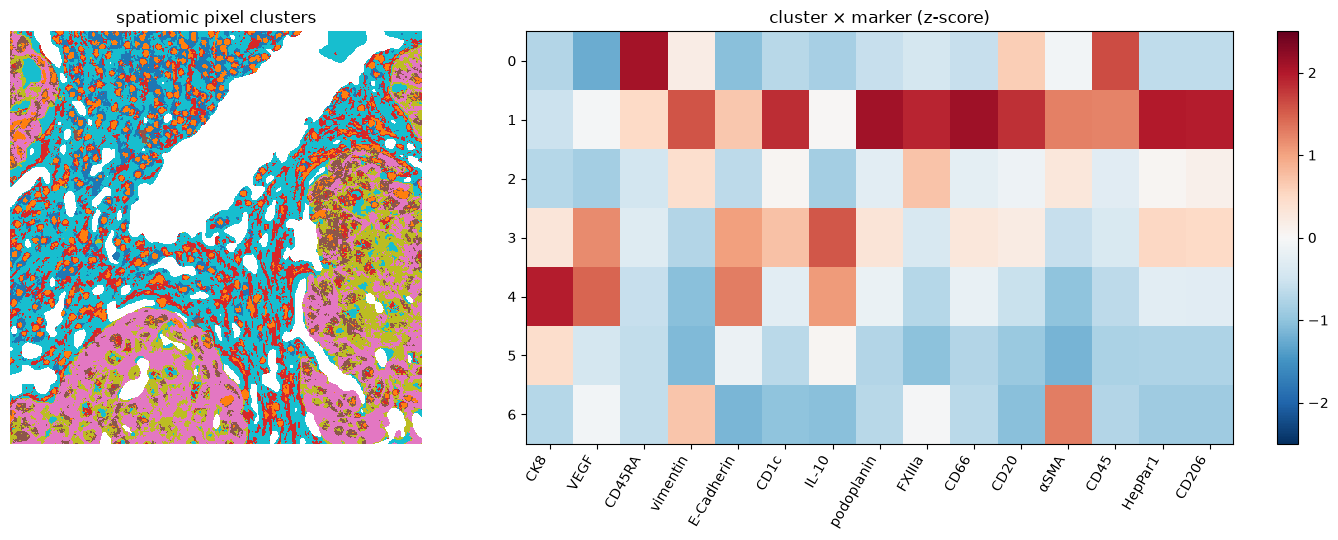

In [9]:
# ── 1. Prepare the input: one 15-marker vector per pixel ────────────────────────────────────────────

# COMET image as a channel-last array (y, x, 15): DAPI dropped (nuclear signal would dominate the clusters),
# cut to the 1000 × 1000 px crop, then downscaled ×2 by averaging 2 × 2 blocks → 500 × 500 px, 15 channels
arr, channels = comet_array(sdata, downscale=2, crop=CROP)

# Tissue mask, precomputed on the whole core at the same ×2 scale, then cut to the crop (//2 for the scale).
# A threshold computed on the crop alone would drop the dim stroma between tumour nests.
# Pixels outside the mask are not used to fit the model and get the label -1.
mask = np.load(PREP / "tissue_mask_ds2.npy")[CROP["y0"] // 2:CROP["y1"] // 2, CROP["x0"] // 2:CROP["x1"] // 2]

# ── 2. spatiomic: segmentation-free pixel clustering ────────────────────────────────────────────────
# Inside run_spatiomic, the steps of the spatiomic full example:
#   a. subsample 20,000 tissue pixels (fitting on every pixel is slow and adds little)
#   b. clip each channel between its 50th and 99.9th percentiles: floors the dim background,
#      caps the few very bright pixels (debris, autofluorescence)
#   c. rescale each channel to [0, 1] so that every marker weighs the same
#   d. fit a 15 × 15 self-organising map (225 nodes, 10 iterations): each node is a prototype pixel profile
#   e. kNN graph between the SOM nodes, then Leiden (resolution 1.0) groups the nodes into clusters
#   f. label every tissue pixel with the cluster of its closest SOM node
res = run_spatiomic(arr, mask, n_pixels=20_000, som_size=(15, 15), iterations=10, resolution=1.0)
labelled = res["labelled"]          # (y, x) map of pixel clusters; -1 = background

# Quality checks:
#   quantisation error = mean distance between a pixel and its SOM node (lower = the map describes the pixels well)
#   modularity        = how well separated the Leiden communities are on the SOM graph (0–1, higher = clearer)
print(f"{labelled.max() + 1} clusters | quantisation error {res['quantization_error']:.3f} | modularity {res['modularity']:.2f}")

# ── 3. Interpret: what each cluster looks like ──────────────────────────────────────────────────────

# Mean normalised intensity of each marker in each cluster (+ number of pixels per cluster)
prof = cluster_profiles(res["img_n"], labelled, channels)

fig, axs = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.6]})

# Left: the cluster map (background masked out so it stays white)
axs[0].imshow(np.ma.masked_less(labelled, 0), cmap="tab10", interpolation="nearest"); axs[0].set_axis_off()
axs[0].set_title("spatiomic pixel clusters")

# Right: cluster × marker heatmap. Each marker is z-scored across clusters, so colour shows which clusters
# are high (red) or low (blue) for that marker relative to the others: that is what you name the clusters from.
P = prof.drop(columns="n_pixels"); P.columns = [c.split(" - ")[0] for c in P.columns]   # "CK8 - TRITC" → "CK8"
im = axs[1].imshow(((P - P.mean()) / P.std()).values, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
axs[1].set_xticks(range(P.shape[1]), P.columns, rotation=60, ha="right"); axs[1].set_yticks(range(len(P)), P.index)
axs[1].set_title("cluster × marker (z-score)"); plt.colorbar(im, ax=axs[1]); plt.tight_layout()

In [10]:
vc, graph, _ = vicinity(labelled, order=2)
(vc.div(vc.sum(axis=1), axis=0) * 100).round(0)   # row = cluster, column = % of its neighbouring pixels in each cluster

,0,1,2,3,4,5,6
0,0.0,23.0,23.0,1.0,0.0,0.0,53.0
1,26.0,0.0,35.0,11.0,6.0,2.0,19.0
2,9.0,19.0,0.0,4.0,1.0,5.0,61.0
3,1.0,11.0,9.0,0.0,42.0,33.0,3.0
4,0.0,5.0,1.0,28.0,0.0,63.0,3.0
5,0.0,2.0,6.0,20.0,55.0,0.0,16.0
6,20.0,9.0,56.0,2.0,3.0,10.0,0.0


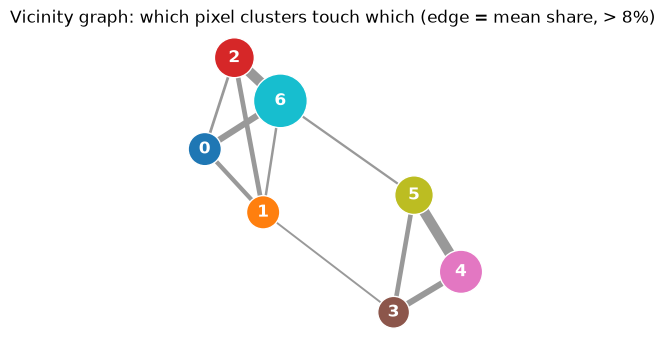

In [28]:
import networkx as nx
from matplotlib.colors import Normalize

# % of each cluster's neighbouring pixels that belong to each other cluster (rows sum to 100)
share = vc.div(vc.sum(axis=1), axis=0) * 100
K = len(share)

# Undirected graph: edge weight = mean of the two directions; keep edges above 8%
G = nx.Graph()
G.add_nodes_from(range(K))
for i in range(K):
    for j in range(i + 1, K):
        w = (share.iloc[i, j] + share.iloc[j, i]) / 2
        if w > 8:
            G.add_edge(i, j, weight=w)

# Same colours as the cluster map (imshow with tab10 over labels 0..K-1)
norm = Normalize(vmin=0, vmax=K - 1)
colors = [plt.cm.tab10(norm(k)) for k in range(K)]
sizes = prof["n_pixels"].reindex(range(K)).to_numpy()          # node size = number of pixels in the cluster

fig, ax = plt.subplots(figsize=(4, 4))
pos = nx.spring_layout(G, weight="weight", seed=0)
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#999999",
                       width=[G[u][v]["weight"] / 8 for u, v in G.edges])
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=300 + 1200 * sizes / sizes.max(),
                       edgecolors="white")
nx.draw_networkx_labels(G, pos, ax=ax, font_color="white", font_weight="bold")
ax.set_title("Vicinity graph: which pixel clusters touch which (edge = mean share, > 8%)")
ax.set_axis_off(); plt.show()

**Question.** Name the clusters from their marker profiles (tumour epithelium, stroma, lymphoid, vessel…).
Which clusters touch which? Is there a cluster that looks bright in *every* channel, and what could it be?

*On the whole core (precomputed, 25 × 25 SOM): `prepared/spatiomic_cluster_profiles.csv` and `spatiomic_vicinity.csv`.*
The crop above has its own small SOM, so its cluster numbers differ from the whole-core ones. Check your names against ours below.

<details>
<summary><b>Answer</b> (click to reveal)</summary>

1. Which clusters touch which

- There are two separate groups. The epithelial clusters (6–10) touch one another. The lymphoid, stroma, vessel-wall, signal-poor and all-bright clusters touch one another.
- Lymphoid and vessel-wall areas almost never touch tumour epithelium (at least 8× less often than chance). In this core, immune cells sit in the stroma, not inside the tumour nests.
- Where the two groups meet, it’s through the dim and signal-poor clusters, not through direct epithelium–immune contact.
-This is only an illustration. It’s one core, and neighbouring pixels aren’t independent samples.

2. The cluster that’s bright in every channel (cluster 5)

A real cell expressing CD20, CD206, CD1c, podoplanin and HepPar1 at once doesn’t exist, so cluster 5 is almost certainly an artefact. The likely causes:
- Autofluorescence, which is strong in liver. Red cells in sinusoids, lipofuscin and haemosiderin pigment, elastin and collagen all glow across channels, and background subtraction doesn’t remove all of it.
- Debris, folds, or tissue lifting at the edges of the core after many staining cycles.
- Non-specific antibody binding in necrotic or damaged areas.

</details>

In [12]:
full = pd.read_csv(PREP / "spatiomic_cluster_profiles.csv", index_col=0)
full = full.drop(columns="n_pixels")
full.columns = [c.split(" - ")[0] for c in full.columns]
full.index = [pixel_cluster_label(k) for k in full.index]   # names: PIXEL_CLUSTER_NAMES in workshop_hcc.py
((full - full.mean()) / full.std()).round(1).style.background_gradient(cmap="RdBu_r", vmin=-2.5, vmax=2.5, axis=None)

,CK8,VEGF,CD45RA,vimentin,E-Cadherin,CD1c,IL-10,podoplanin,FXIIIa,CD66,CD20,αSMA,CD45,HepPar1,CD206
0 · Dim tissue,-0.700000,-0.300000,-0.300000,-0.100000,-0.500000,0.700000,-0.600000,-0.600000,-0.600000,-0.500000,0.400000,-0.000000,-0.200000,0.300000,0.300000
"1 · Lymphoid (CD45, CD45RA)",-0.700000,-0.900000,2.900000,0.200000,-0.900000,-0.400000,-0.800000,-0.400000,0.000000,-0.400000,1.000000,-0.000000,2.600000,-0.400000,-0.400000
2 · Signal-poor,-0.700000,1.000000,-0.400000,-0.400000,-1.000000,-0.700000,-1.000000,-0.900000,0.900000,-0.900000,-0.800000,-0.600000,-0.600000,-0.700000,-0.700000
3 · Stroma (vimentin),-0.700000,-0.600000,-0.400000,2.800000,-0.800000,-0.700000,-0.800000,0.600000,0.600000,0.400000,-0.600000,-0.200000,-0.300000,-0.400000,-0.400000
4 · Vessel wall (αSMA),-0.700000,-1.200000,-0.500000,0.000000,-1.000000,-0.700000,-1.000000,-0.700000,-0.700000,-0.600000,-0.800000,2.800000,-0.600000,-0.700000,-0.600000
5 · All-bright (autofluorescence),-0.500000,0.400000,0.300000,0.500000,0.800000,2.300000,0.600000,2.500000,2.500000,2.600000,2.300000,0.700000,1.100000,2.500000,2.600000
6 · Tumour–immune interface,-0.000000,0.500000,-0.200000,-0.600000,0.300000,0.500000,1.100000,0.300000,-0.400000,0.200000,0.200000,-0.400000,-0.300000,0.400000,0.300000
"7 · Epithelium, CK8 dim",-0.200000,-0.400000,-0.400000,-0.600000,-0.200000,-0.600000,0.200000,-0.800000,-0.900000,-0.800000,-0.700000,-0.600000,-0.600000,-0.700000,-0.700000
"8 · Epithelium, CK8+",0.900000,-0.600000,-0.500000,-0.700000,0.000000,-0.700000,-0.100000,-0.700000,-0.800000,-0.700000,-0.800000,-0.600000,-0.600000,-0.700000,-0.700000
"9 · Epithelium, CK8+ VEGF+ IL-10+",1.500000,2.300000,-0.200000,-0.500000,1.100000,1.000000,2.100000,0.800000,-0.100000,0.800000,0.600000,-0.300000,-0.000000,0.900000,0.900000


## 4 · From pixels to cells, then a joint embedding
The bridge between the two levels: for each Xenium cell, the fraction of its pixels in each spatiomic cluster.
That gives a third cell-level block, next to RNA and protein.

In [13]:
# ── 1. Pixels → cells: what fraction of each cell is covered by each spatiomic cluster ──────────────

# Xenium cell outlines (polygons), moved into the shared "global" frame (COMET pixel grid)
geo = in_global("cell_boundaries")

# Keep the cells whose centre falls inside the crop on which spatiomic was run
inside = geo.centroid.x.between(CROP["x0"], CROP["x1"]) & geo.centroid.y.between(CROP["y0"], CROP["y1"])
ids = list(geo.index[inside].astype(str))

# Draw each polygon into a label image the same size as the pixel-cluster map (0 = no cell, i = i-th cell).
# origin shifts the coordinates to the crop's corner; scale=2 because the COMET crop was downscaled ×2.
cell_mask = rasterize_cells(geo[inside].values, ids, labelled.shape, origin=(CROP["x0"], CROP["y0"]), scale=2)

# Overlay cell mask and pixel clusters: for each cell, the fraction of its pixels in each cluster
# → a cells × k table (rows sum to 1). This is the bridge from the pixel level to the cell level.
comp = pixel_composition(cell_mask, labelled, ids)

# ── 2. Three blocks on the same cells: RNA, protein, pixel composition ──────────────────────────────

# Subset the cell table to the cells in the crop, and put the composition rows in the same order
# (cells with no pixel inside the tissue mask get 0 everywhere)
a = t[t.obs["cell_id"].astype(str).isin(comp.index)].copy()
comp = comp.reindex(a.obs["cell_id"].astype(str)).fillna(0.0)

# RNA block: standard scanpy steps on raw counts → normalise per cell, log, 20 principal components
a.X = a.layers["counts"].copy(); sc.pp.normalize_total(a); sc.pp.log1p(a); sc.pp.pca(a, n_comps=20)

# Protein block: per-cell mean COMET intensities (15 markers, DAPI dropped), log, z-scored per marker
prot = np.log1p(a.obsm["protein"].drop(columns="DAPI")); prot = (prot - prot.mean()) / prot.std()

# ── 3. Early fusion with block scaling ──────────────────────────────────────────────────────────────

# block_scale centres each block and divides it by sqrt(its total variance), so each block has total
# variance 1. Without it, the block with the most columns or the largest values would dominate the PCA.
blocks = [block_scale(a.obsm["X_pca"]), block_scale(prot.values), block_scale(comp.values)]

# Concatenate the three blocks side by side (20 + 15 + k columns), then one PCA → the joint embedding
a.obsm["X_joint"] = PCA(20, random_state=0).fit_transform(np.hstack(blocks))

# ── 4. Cluster both views the same way (RNA only vs joint) ──────────────────────────────────────────

# For each embedding: kNN graph in that space, then Leiden with the same settings, so the two are comparable
for rep in ["X_pca", "X_joint"]:
    sc.pp.neighbors(a, use_rep=rep, key_added=rep)
    sc.tl.leiden(a, neighbors_key=rep, key_added=f"leiden_{rep}",
                 resolution=0.8, flavor="igraph", n_iterations=2)

# ── 5. Compare the two clusterings ──────────────────────────────────────────────────────────────────

# Each cell's dominant pixel cluster (the one covering most of its pixels): the segmentation-free reference
dominant = comp.values.argmax(1)
xy = a.obsm["spatial"]   # cell centroids, used only for the evaluation, never for clustering

summary = pd.DataFrame({name: {
        "clusters": a.obs[col].nunique(),
        # fraction of each cell's 10 spatial nearest neighbours that share its cluster (mean over cells)
        "spatial coherence": spatial_coherence(xy, a.obs[col].astype(str).values),
        # agreement with the dominant pixel cluster: 1 = identical partitions, 0 = chance
        "ARI vs pixel clusters": adjusted_rand_score(a.obs[col], dominant)}
    for name, col in [("RNA only", "leiden_X_pca"), ("joint", "leiden_X_joint")]}).T

print(f"{a.n_obs} cells in the crop"); summary.round(2)

719 cells in the crop


,clusters,spatial coherence,ARI vs pixel clusters
RNA only,7.0,0.47,0.26
joint,9.0,0.33,0.30


,embedding,n_clusters,spatial_coherence_k10,ARI_vs_pixel_dominant,ARI_vs_cell_type
0,rna,11,0.55,0.16,0.33
1,protein,13,0.24,0.19,0.15
2,joint,11,0.37,0.33,0.24
3,joint_shuffled,10,0.22,0.09,0.20
4,pixel_dominant,11,0.29,1.00,0.14


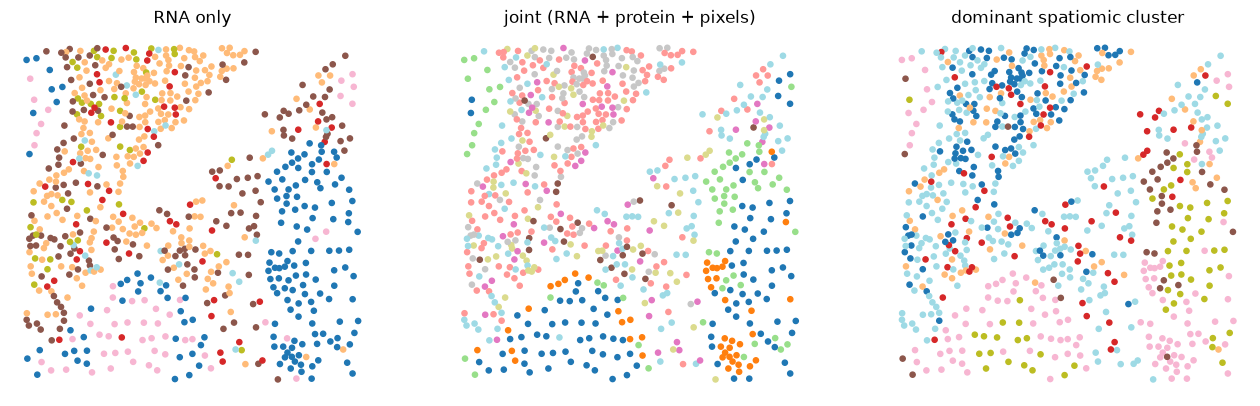

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, (vals, title) in zip(axs, [(a.obs["leiden_X_pca"], "RNA only"), (a.obs["leiden_X_joint"], "joint (RNA + protein + pixels)"),
                                   (dominant, "dominant spatiomic cluster")]):
    ax.scatter(xy[:, 0], xy[:, 1], c=pd.Categorical(vals).codes, cmap="tab20", s=14)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_axis_off(); ax.set_title(title)
pd.read_csv(PREP / "integration_metrics.csv").round(2)   # the same, on the whole core (with a shuffled-layer control)

**Question.** The shuffled control (protein and pixel blocks permuted across cells) loses most of its spatial coherence:
what does that tell you? Why might the RNA-only clustering look *more* spatially coherent than the joint one?

<details>
<summary><b>Answer</b> (click to reveal)</summary>
    
1. What the shuffled control tells you

- Coherence on the whole core goes from 0.37 (joint) to 0.22 when the protein and pixel blocks are shuffled across cells. Agreement with the pixel clusters (ARI) falls from 0.33 to 0.09.
- So the protein and pixel blocks carry real information tied to each cell and organised in space. The joint embedding isn’t just RNA plus noise.
- It also confirms the pipeline matched cells correctly. If the Xenium–COMET matching were wrong, the real joint embedding would look like the shuffled one.
- The shuffled version scores below RNA-only (0.22 vs 0.55). That shows block scaling really gives each block equal weight: two-thirds of the input became noise, and the result got worse.

2. Why RNA-only can look more spatially coherent than the joint embedding

- The metric rewards large, smooth domains. Clustering by position alone would score highest. Higher coherence isn’t automatically better biology.
- RNA is smoothed in space by artefacts. Transcripts spill between neighbouring cells, and diffusion and the Xenium segmentation do the same, so neighbours look alike.
- Protein and pixels pick out fine-grained states that break up smooth domains. Examples are single immune cells inside tumour nests, interface cells, and αSMA⁺ cells around vessels.
- They’re also noisier per cell. Autofluorescence, uneven staining and the all-bright cluster add noise.
- Coherence alone can’t tell you which embedding is better. Read it alongside agreement with the pixel clusters (the joint embedding wins there) and with the biology.

</details>

## 4b · One multilayer network on the same cells (optional)
Another way to fuse: each modality becomes a graph **layer** on the same nodes (the 8,290 Xenium cells): cells are linked
when they are similar in RNA, in protein, or in pixel composition. The shared segmentation is what makes the nodes the same.
Two questions: do the layers agree on who is similar, and what do they find together?

In [15]:
# ── Build one multilayer network: same nodes (the 8,290 Xenium cells), one edge layer per modality ──
# Each network is a similarity network based on some modality key information

t = sdata.tables["table"]            # cell table: one row per Xenium cell (the shared segmentation)

# RNA layer input: raw counts → normalise per cell → log → 30 principal components
rna = t.copy(); rna.X = rna.layers["counts"].copy()
sc.pp.normalize_total(rna); sc.pp.log1p(rna); sc.pp.pca(rna, n_comps=30, random_state=0)

# Protein layer input: per-cell mean COMET intensities (15 markers, DAPI dropped).
# The few cells without a protein value (outside the COMET image or mask) get the median of each marker.
prot = t.obsm["protein"].drop(columns=["DAPI"]); prot = prot.fillna(prot.median())
# log, then z-score each marker so that bright and dim antibodies weigh the same
prot_z = ((np.log1p(prot) - np.log1p(prot).mean()) / np.log1p(prot).std()).values

# Pixel layer input: per-cell composition in the 11 whole-core spatiomic clusters (precomputed;
# same idea as section 4, but on the whole core). Reordered to match the cell table; cells with no
# tissue pixel get 0 everywhere.
comp_all = pd.read_csv(PREP / "pixel_composition.csv", index_col=0).reindex(t.obs["cell_id"].astype(str)).fillna(0).values

# One graph per modality: each cell is linked to its 15 nearest neighbours in that modality's feature space.
# The graph is made symmetric (an edge if either cell is in the other's top 15) and binary (no weights).
# No cell coordinates are used: "neighbour" here means similar in expression, not close in the tissue.
layers = {"RNA": knn_layer(rna.obsm["X_pca"]),
          "protein": knn_layer(prot_z),
          "pixels": knn_layer(comp_all)}

# How much do the modalities agree on who is similar?
# For each pair of layers: Jaccard index of their edge sets = shared edges / edges in either layer.
# 1 = the two layers link exactly the same pairs of cells; 0 = no edge in common.
layer_agreement(layers).round(3)

,RNA,protein,pixels
RNA,1.000,0.013,0.008
protein,0.013,1.000,0.042
pixels,0.008,0.042,1.000


In [16]:
xy, ct = t.obsm["spatial"], t.obs["cell_type"].astype(str).values
views = {name: multiplex_leiden({name: A}) for name, A in layers.items()}
views["multilayer"] = multiplex_leiden(layers)          # communities shared by the three layers
pd.DataFrame({k: {"communities": len(set(v)), "spatial coherence": round(spatial_coherence(xy, v.astype(str), 10), 3),
                  "ARI vs cell types": round(adjusted_rand_score(ct, v), 3)} for k, v in views.items()}).T

,communities,spatial coherence,ARI vs cell types
RNA,11.0,0.562,0.301
protein,13.0,0.258,0.155
pixels,17.0,0.227,0.122
multilayer,6.0,0.541,0.359


**Network exploration.** A random walk with restart (MultiXrank, Baptista et al., *Commun Phys* 2022) starts from seed
cells, moves along edges within a layer, jumps between layers, and keeps returning to the seeds. Cells that score high are
close to the seeds *in all modalities at once*. Seeds here: the B cells. No cell coordinates are used.

top-500 neighbours of the B cells: {'T cell': 428, 'Fibroblast / stellate': 26, 'Macrophage': 19, 'Dendritic cell': 18}
median distance to the nearest B cell: top-500 10 µm, random cells 75 µm


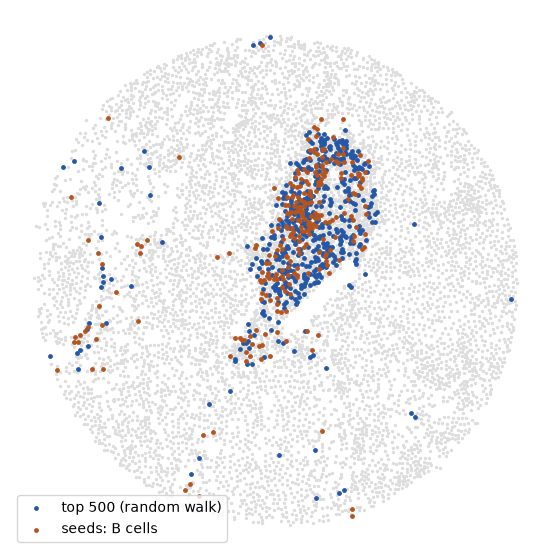

In [17]:
# Seeds = the starting points of the walk: every cell labelled "B cell" by the RNA cell typing
seeds = np.where(ct == "B cell")[0]

# The walker moves on the three layers (RNA, protein, pixels), which share the same cells as nodes:
#   - at each step it follows an edge inside its current layer (to a cell similar in that modality),
#   - with probability delta = 0.5 it jumps to the same cell in another layer (switches modality),
#   - with probability restart = 0.7 it goes back to a random seed.
# The score is how often the walker visits each cell in the long run (geometric mean over the layers).
# High score = close to the B cells in all modalities at once. No coordinates are used.
score = multiplex_rwr(layers, seeds, restart=0.7, delta=0.5)

# The 500 highest-scoring cells, excluding the seeds themselves
top = [i for i in np.argsort(-score) if i not in set(seeds)][:500]

# Which cell types does the walk reach?
print("top-500 neighbours of the B cells:", pd.Series(ct[top]).value_counts().head(4).to_dict())

# ── The test: are these cells also close to the B cells in the tissue? ──────────────────────────────
# Only now are the coordinates used, to evaluate the result.
from scipy.spatial import cKDTree

# For each top-500 cell: distance to the nearest B cell (COMET pixels → µm)
d_top = cKDTree(xy[seeds]).query(xy[top])[0] * COMET_UM_PER_PX

# Baseline: the same for 500 cells drawn at random from the core (seeded, so reproducible)
d_rnd = cKDTree(xy[seeds]).query(xy[np.random.default_rng(0).choice(len(ct), 500, replace=False)])[0] * COMET_UM_PER_PX

print(f"median distance to the nearest B cell: top-500 {np.median(d_top):.0f} µm, random cells {np.median(d_rnd):.0f} µm")

# ── Map: where are the seeds and the cells the walk found? ──────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(xy[:, 0], xy[:, 1], c="#DDDDDD", s=2)                                         # all cells (grey)
ax.scatter(xy[top, 0], xy[top, 1], c="#2457A6", s=6, label="top 500 (random walk)")       # found by the walk (blue)
ax.scatter(xy[seeds, 0], xy[seeds, 1], c="#B4541F", s=6, label="seeds: B cells")          # seeds (orange)
ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_axis_off(); ax.legend(loc="lower left")  # image orientation: y down

**Question.** The layers share only a few % of their edges, yet the walk lands next to the B cells, in tissue space,
without ever seeing coordinates. What does that say about the lymphoid aggregate? Try other seeds (macrophages,
endothelial cells), or drop one layer from `layers` and compare.

<details>
<summary><b>Answer</b> (click to reveal)</summary>

- The three layers share only 1–4% of their kNN edges, but seeding from the B cells gives a top 500 that’s 261 T cells. Their median distance to the nearest B cell is 9 µm, against 77 µm for random cells.
- So the aggregate is coherent in every modality. In RNA, protein (CD45, CD45RA, CD20) and pixel composition, its cells resemble each other more than they resemble anything else.
- The layers disagree on which particular cells are neighbours, but they agree on the community. The walk combines them, so where-it-ends-up comes out of identity alone: it’s a real niche, possibly a tertiary lymphoid structure.
- One caveat for the room: the walk isn’t completely blind to space. A cell’s protein value and pixel composition include signal from its neighbours (spillover, mask overlap). In a dense aggregate, that puts some spatial information into the layers.

</details>

## 5 · In pairs: RNA vs protein

,protein,gene,spearman,gene_detected_frac
0,E-Cadherin,CDH1,0.46,0.29
1,VEGF,VEGFA,0.35,0.31
2,FXIIIa,F13A1,0.19,0.03
3,CD20,MS4A1,0.19,0.03
4,IL-10,IL10,0.05,0.01
5,CD1c,CD1C,0.04,0.01
6,HepPar1,CPS1,0.02,0.04
7,CD66,CEACAM1,0.02,0.07
8,podoplanin,PDPN,-0.01,0.00
9,CD206,MRC1,-0.01,0.04


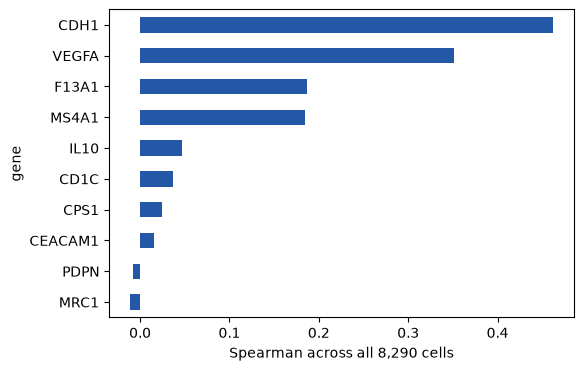

In [18]:
counts = pd.DataFrame(t.layers["counts"], index=t.obs_names, columns=t.var_names)
conc = rna_protein_concordance(counts, t.obsm["protein"])
ax = conc.plot.barh(x="gene", y="spearman", legend=False, figsize=(6, 4), color="#2457A6"); ax.invert_yaxis()
ax.set_xlabel("Spearman across all 8,290 cells"); conc.round(2)

In [19]:
# Sparse RNA makes per-cell correlations low. Another view: among protein-positive cells, how often is the RNA detected?
pos = {"MS4A1": "CD20_-_TRITC_positive", "VEGFA": "VEGF_-_TRITC_positive", "CDH1": "E-Cadherin_-_TRITC_positive"}
pd.DataFrame({g: {"RNA detected | protein+": (counts[g][t.obs[c]] > 0).mean(),
                  "RNA detected | protein−": (counts[g][~t.obs[c]] > 0).mean()} for g, c in pos.items()}).T.round(2)

,RNA detected | protein+,RNA detected | protein−
MS4A1,0.56,0.02
VEGFA,0.06,0.31
CDH1,0.52,0.24


Discuss with your neighbour:

* Which markers agree between RNA and protein, and which don't? Is the disagreement **biology** (secretion, post-transcriptional
  regulation, half-life) or **technology** (segmentation, spillover from neighbours, probe or antibody quality, RNA dropout)?
* Do pixel clusters split cells that the RNA clustering lumps together? Find one such cell and look at it in the images (section 1).
* What does the protein layer show that the transcriptome alone doesn't?

## 5b · Cell typing with RNA + protein markers (optional)
The labels above use RNA only. `annotate_multiomic` (in `workshop_hcc.py`) keeps the multispace marker logic and adds the
protein layer:

1. **Clusters on RNA + protein**: 30 RNA PCs and the 15 COMET intensities (log, z-scored per channel), each block scaled to
   the same total variance; Leiden at resolution 2.0, as for the RNA-only labels.
2. **A protein score next to the RNA score.** Protein decides the *compartment*, where the 5K panel is weakest:
   immune = CD45 (instead of the missing PTPRC), epithelial = CK8, E-cadherin, HepPar1, stromal = vimentin. Each score is a
   contrast (own compartment minus the others), after removing each cell's overall brightness. Within a compartment, one
   specific protein where the panel has one: CD20/CD45RA (B), CD206/FXIIIa (macrophage), CD1c (DC), αSMA (fibroblast).
3. **Score = ½ RNA + ½ protein**, then one label per cluster with multispace's quality gates.

Configuration: `PROTEIN_LINEAGES`, `PROTEIN_SPECIFIC`, `CELL_TYPE_LINEAGE` in `workshop_hcc.py`.

In [20]:
mo = annotate_multiomic(t, protein_weight=0.5)          # writes obs['cell_type_multiomic']
print(f"{(t.obs['cell_type'].astype(str) == t.obs['cell_type_multiomic'].astype(str)).mean():.0%} of cells keep their RNA label")
pd.crosstab(t.obs["cell_type"], t.obs["cell_type_multiomic"], rownames=["RNA only"], colnames=["RNA + protein"])

85% of cells keep their RNA label


RNA + protein,B cell,Endothelial,Fibroblast / stellate,HCC tumour,Hepatocyte,Macrophage,T cell
RNA only,,,,,,,
B cell,174,4,5,0,0,1,81
Dendritic cell,11,1,5,0,0,9,47
Endothelial,0,201,9,0,0,3,3
Fibroblast / stellate,8,146,1011,3,0,8,54
HCC tumour,12,22,77,3833,317,64,28
Hepatocyte,0,1,0,44,254,0,0
Macrophage,8,15,16,2,0,311,28
T cell,101,8,31,9,0,34,1291


In [21]:
# Each modality's own winner per cluster: where RNA and protein disagree, which one won?
mo[["n_cells", "rna_winner", "protein_winner", "cell_type_multiomic", "ambiguity_ratio"]].sort_values("cell_type_multiomic")

,n_cells,rna_winner,protein_winner,cell_type_multiomic,ambiguity_ratio
multiomic_cluster,,,,,
25,240,B cell,B cell,B cell,1.636053
26,74,Dendritic cell,B cell,B cell,1.177785
13,371,Endothelial,Endothelial,Endothelial,1.029955
16,27,HCC tumour,Endothelial,Endothelial,1.396576
14,317,Fibroblast / stellate,Fibroblast / stellate,Fibroblast / stellate,3.043289
17,158,Fibroblast / stellate,Fibroblast / stellate,Fibroblast / stellate,1.727917
18,430,Fibroblast / stellate,Fibroblast / stellate,Fibroblast / stellate,1.958602
24,76,Neutrophil,Fibroblast / stellate,Fibroblast / stellate,1.875157
27,173,Fibroblast / stellate,Fibroblast / stellate,Fibroblast / stellate,2.302119


one_to_one                 False  True 
change                                 
HCC tumour <-> hepatocyte  0.039  0.078
compartment                0.072  0.030
same                       0.811  0.847
within compartment         0.077  0.045


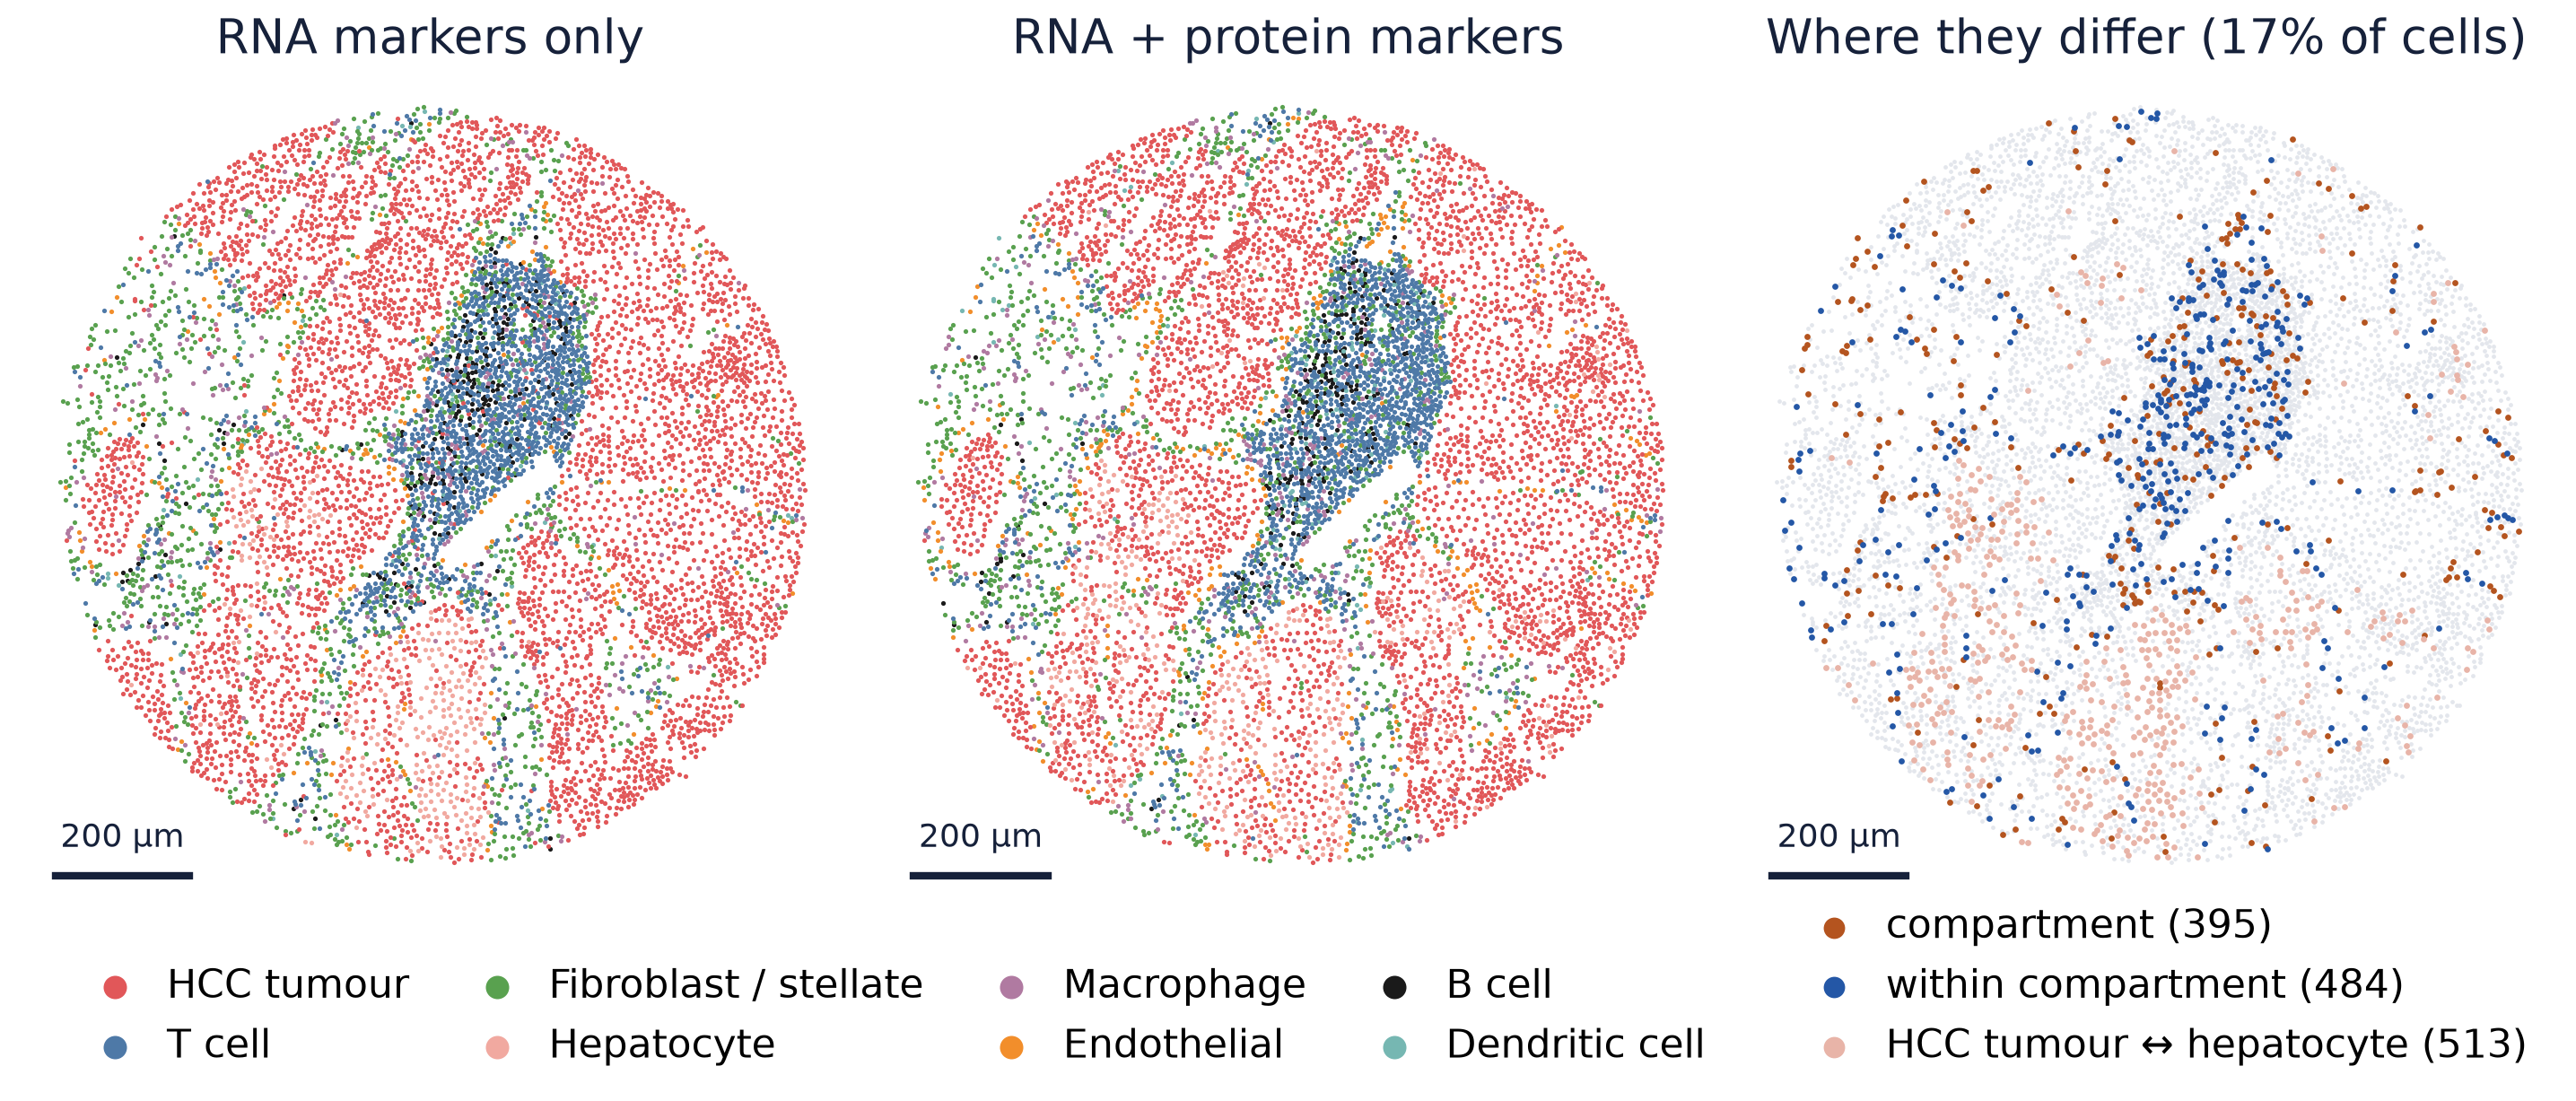

In [22]:
# Precomputed with the Xenium–COMET segmentation match: are label changes more frequent where the segmentations disagree?
cm = pd.read_csv(PREP / "cell_typing_multiomic" / "cells.csv", index_col=0)
print(pd.crosstab(cm["change"], cm["one_to_one"], normalize="columns").round(3))
display(Image("figures/18_multiomic_cell_types.png", width=1000))

**Questions.**

* 165 cells go from "HCC tumour" (RNA) to an immune type (protein: CD45+, CK8−). Find a few
  (`t.obs.query("cell_type == 'HCC tumour' and cell_type_multiomic != 'HCC tumour'")`) and look at them in the images
  (section 1): immune cells inside the tumour, or tumour cells picking up a neighbour's CD45?
* Compartment changes happen in 7% of cells without a one-to-one COMET cell vs 3% of matched cells. What does that tell you
  about where the protein value of a cell comes from?
* Re-run with `protein_weight=0.25` and `0.75`. Which labels are stable?
* Run `PROTEIN_SPECIFIC["Neutrophil"] = ["CD66"]`, then `annotate_multiomic(t)` again. What happens to the lymphoid
  aggregate, and why? (Hint: the CD66 antibody also sees CEACAM1, found on activated T cells.) `del PROTEIN_SPECIFIC["Neutrophil"]` to undo.

<details>
<summary><b>Answer</b> (click to reveal)</summary>

- HCC tumour → immune: mostly segmentation mismatch. Only 29% of these cells have a one-to-one COMET cell (59% overall), with median mask overlap 0.17 (0.58 overall). The Xenium outline covers part of an immune neighbour, so its CD45 gets counted. A few are real immune cells in the nests: look for a compact nucleus with CD45 all around the membrane, rather than a CD45 crescent on one edge.
- 7% vs 3%: a cell’s protein value is whatever falls inside its Xenium mask. Without a matched COMET cell, that mixes in neighbours or background, so labels flip more than twice as often. Protein is only as good as the shared segmentation.
- protein_weight (expected; participants should check): T cells, B-cell cores, macrophages and the bulk of the tumour are likely stable. The likely movers are tumour ↔ hepatocyte (HepPar1), fibroblast ↔ endothelial (vimentin), and DCs and B/T cells inside the aggregate. Labels that change are where the modalities disagree.
- CD66 as a neutrophil marker: activated T cells in the aggregate become “neutrophils”, because the antibody also binds CEACAM1. A neutrophil-rich lymphoid aggregate is implausible. Check antibody specificity before using a marker to decide a label.

</details>

## 5c · Who sits next to whom: neighbourhood enrichment
Cell types answer *what* is there; this asks *who sits next to whom* (slide 5: colocalisation). multispace's
`run_spatial_analysis` builds a Delaunay graph on the cell centroids (each cell linked to its touching neighbours, here it is a spatial network instead of ot the one define in section 4b), counts
the links between every pair of cell types, and compares them with 1,000 random shuffles of the labels (squidpy
`nhood_enrichment`). **z > 0**: the two types touch more often than chance; **z < 0**: they avoid each other.
Everything below runs live, in a few seconds.

In [23]:
# ── Neighbourhood enrichment: which cell types touch each other more (or less) often than by chance? ──
# Method, the same for all three runs:
#   1. Delaunay graph on the cell centroids: each cell is linked to the cells that touch it
#   2. count the links between every pair of cell types
#   3. shuffle the cell-type labels 1,000 times (positions fixed) and count again → what chance gives
#   4. z-score = (observed − mean of the shuffles) / sd of the shuffles
#      z > 0: the two types are neighbours more often than chance; z < 0: they avoid each other

# core01, RNA-only labels, with multispace (the same call works on any SpatialData object in the multispace contract).
# sections=["neighborhood"] runs only that analysis; results (tables, plots) are written to results_dir.
res = ms.run_spatial_analysis(sdata, results_dir="results/nhood_rna", sections=["neighborhood"], cluster_key="cell_type")
z_rna = res["nhood_enrichment_zscore"]          # cell type × cell type table of z-scores

# core01, RNA + protein labels (section 5b): same cells, same positions, only the labels change.
# If you skipped 5b, the labels are read from the precomputed table, in the same cell order (t.obs_names).
if "cell_type_multiomic" not in t.obs:
    t.obs["cell_type_multiomic"] = pd.read_csv(PREP / "cell_typing_multiomic" / "cells.csv", index_col=0) \
        .loc[t.obs_names, "cell_type_multiomic"].to_numpy()
z_mo = ms.run_spatial_analysis(sdata, results_dir="results/nhood_multiomic", sections=["neighborhood"],
                               cluster_key="cell_type_multiomic")["nhood_enrichment_zscore"]

# core02 (non-tumour): there is no SpatialData object here, only its cell table (centroids + RNA labels).
# nhood_zscore repeats the same steps directly with squidpy (Delaunay graph, 1,000 permutations),
# so the three tables are comparable.
obs2 = pd.read_csv(PREP / "core02" / "integration_obs.csv", index_col=0)
z_02 = nhood_zscore(obs2[["x", "y"]].to_numpy(), obs2["cell_type"])

INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  


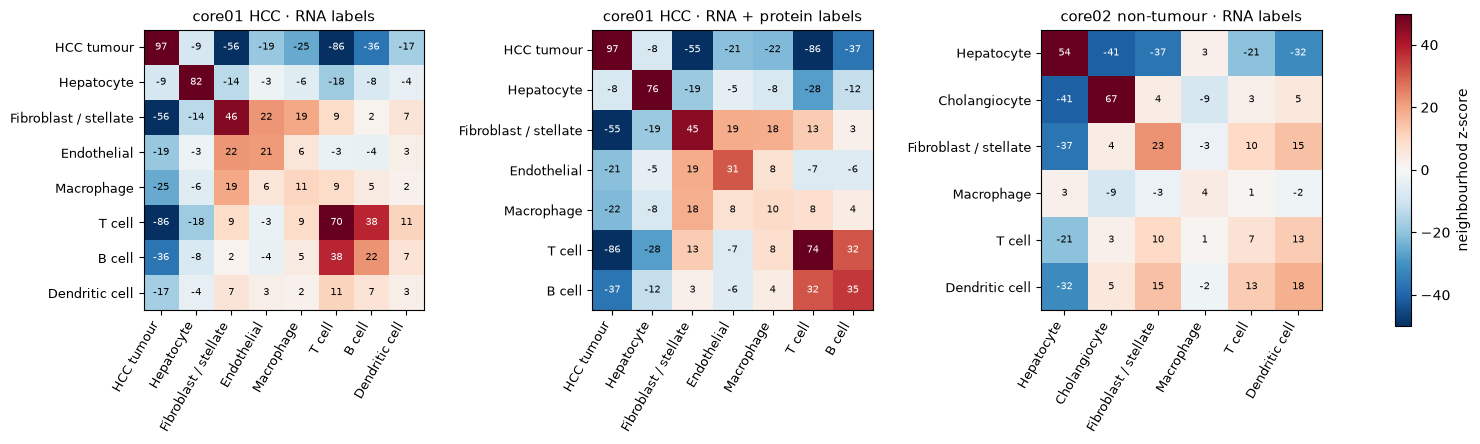

In [24]:
order = ["HCC tumour", "Hepatocyte", "Cholangiocyte", "Fibroblast / stellate", "Endothelial", "Macrophage",
         "T cell", "B cell", "Dendritic cell"]
fig, axs = plt.subplots(1, 3, figsize=(19, 5.8), gridspec_kw={"wspace": 0.6})
for ax, (z, ttl) in zip(axs, [(z_rna, "core01 HCC · RNA labels"), (z_mo, "core01 HCC · RNA + protein labels"),
                              (z_02, "core02 non-tumour · RNA labels")]):
    im = plot_nhood(z, ax, ttl, order=order)
fig.colorbar(im, ax=axs, shrink=0.7, label="neighbourhood z-score"); plt.show()

In [25]:
# A few pairs side by side (NaN: one of the two types is absent from that core)
pairs = [("T cell", "B cell"), ("T cell", "HCC tumour"), ("Macrophage", "HCC tumour"), ("Macrophage", "Hepatocyte"),
         ("Macrophage", "Fibroblast / stellate"), ("Endothelial", "Fibroblast / stellate")]
get = lambda z, a, b: z.loc[a, b] if a in z.index and b in z.index else np.nan
pd.DataFrame({f"{a} – {b}": {"core01 RNA": get(z_rna, a, b), "core01 RNA + protein": get(z_mo, a, b),
                              "core02 RNA": get(z_02, a, b)} for a, b in pairs}).T.round(1)

,core01 RNA,core01 RNA + protein,core02 RNA
T cell – B cell,38.0,31.5,NaN
T cell – HCC tumour,-86.2,-85.7,NaN
Macrophage – HCC tumour,-25.3,-21.9,NaN
Macrophage – Hepatocyte,-6.0,-7.9,2.6
Macrophage – Fibroblast / stellate,19.5,18.3,-3.0
Endothelial – Fibroblast / stellate,21.9,18.6,NaN


**Questions.**

* On the HCC core, T cells avoid tumour cells (z ≈ −86) and sit with B cells (z ≈ +38). Immune exclusion, or simply
  two compartments (tumour nests vs the lymphoid aggregate)? What would you need to tell them apart?
* Macrophages avoid tumour nests in core01 but mix with hepatocytes in core02 (Kupffer cells live in the sinusoids).
  Same label, different neighbourhood: what does that say about using one "macrophage" class across conditions?
* Do the RNA + protein labels change any conclusion? Which pairs move most, and is it the cell typing or the biology?
* z-scores grow with the number of cells: compare **signs and ranks** between cores, not the raw values. And it is one
  core per condition: an illustration, not a test.

<details>
<summary><b>Answer</b> (click to reveal)</summary>

- Exclusion or compartments? These z-scores alone can’t tell, because one aggregate beside tumour nests gives the same pattern. You’d need T-cell density against distance to the tumour edge (nest, margin, stroma), a null model that shuffles labels within compartments, T-cell states, and more cores.
- Macrophages: in core01 the class likely mixes tumour-associated macrophages with Kupffer cells, which have different origins and locations. One class across conditions hides that. Split it by subtype, or describe the difference as tissue structure, not macrophage behaviour.
- RNA + protein labels: no conclusion changes, and every sign is kept. T–B moves most (38 → 31.5) because about 180 cells swap between B and T in the aggregate. Since the tissue is the same, the change comes from the cell typing, not the biology.
- Between cores: compare signs and ranks only. Macrophage–hepatocyte flips from −6.0 to +2.6, and macrophage–fibroblast from +19.5 to −3.0.

</details>

## 6 · Tumour vs non-tumour: core01 vs core02 
`core02_non_tumour` is non-tumour liver from the same TMA slide, prepared with `prepare_core02.py` (same steps as core01).
To compare pixel clusters, **one** spatiomic SOM model was fitted on pixels pooled from both cores (30,000 per core), so
cluster *k* is the same phenotype in both. Two things went wrong on the way, and they are worth seeing:

* **The core01 SOM model does not describe core02.** Labelling core02 with the core01-only SOM model gives a quantisation error of
  0.45, against 0.13 on core01: normal liver contains pixel phenotypes the tumour core never showed the SOM model.
* **core02 is 2–5× brighter in every channel.** With one shared normalisation, 8 of the 11 joint clusters come ≥ 90% from a
  single core: the SOM model separates the cores by brightness (autofluorescence, staining, exposure), not by biology. Normalising
  each core with its own percentiles first fixes this, and removes any true global difference along with it.

{'model': 'joint spatiomic model, 30k pixels per core, per_core_norm=True', 'n_clusters': 11, 'quantization_error_joint': 0.13643478876873458, 'modularity': 0.7370825920450658, 'qe_core01': 0.14339723238017418, 'qe_core02': 0.13124069912810823, 'qe_core02_with_core01_model': 0.44503545702024666, 'qe_core01_with_core01_model': 0.12925229892959697, 'downscale': 2}


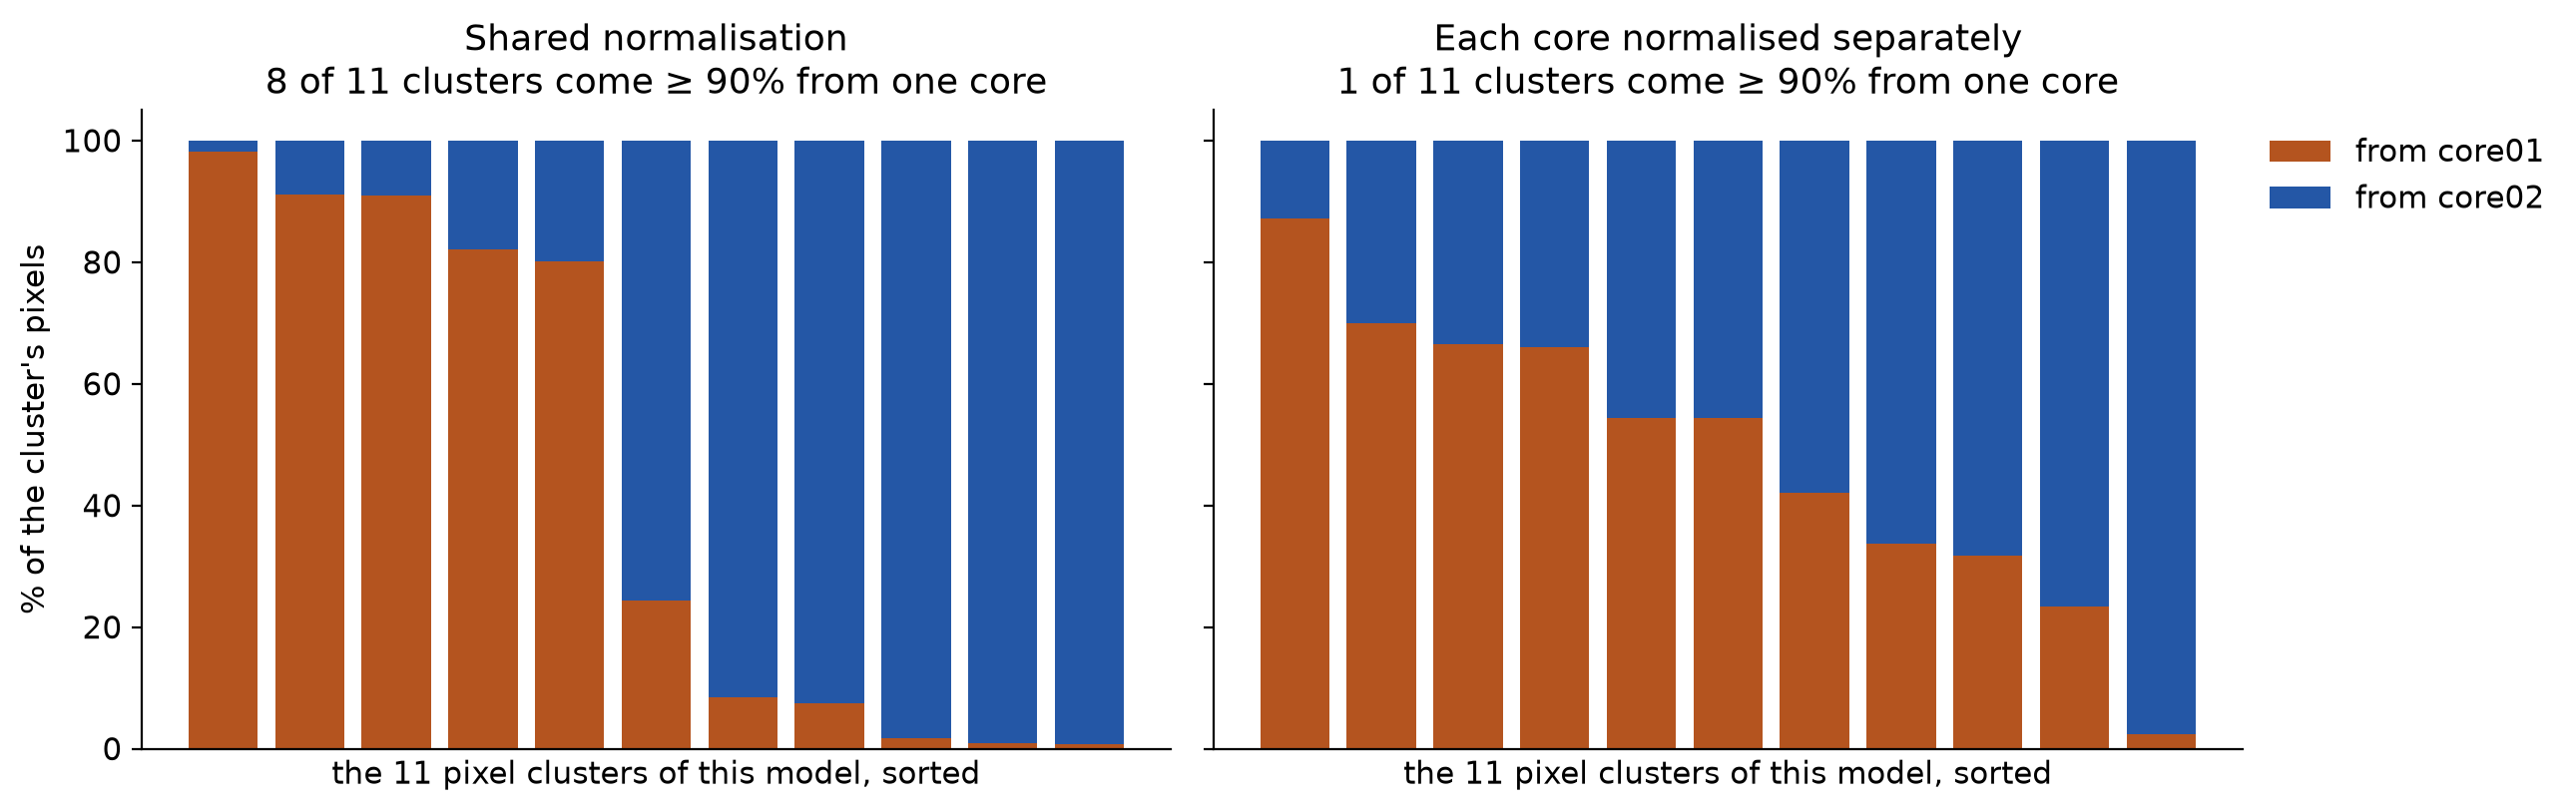

In [26]:
C2 = PREP / "core02"
print(json.load(open(C2 / "joint" / "run.json")))   # quantisation errors of the three SOM models
display(Image("figures/15_normalisation_pitfall.png", width=900))

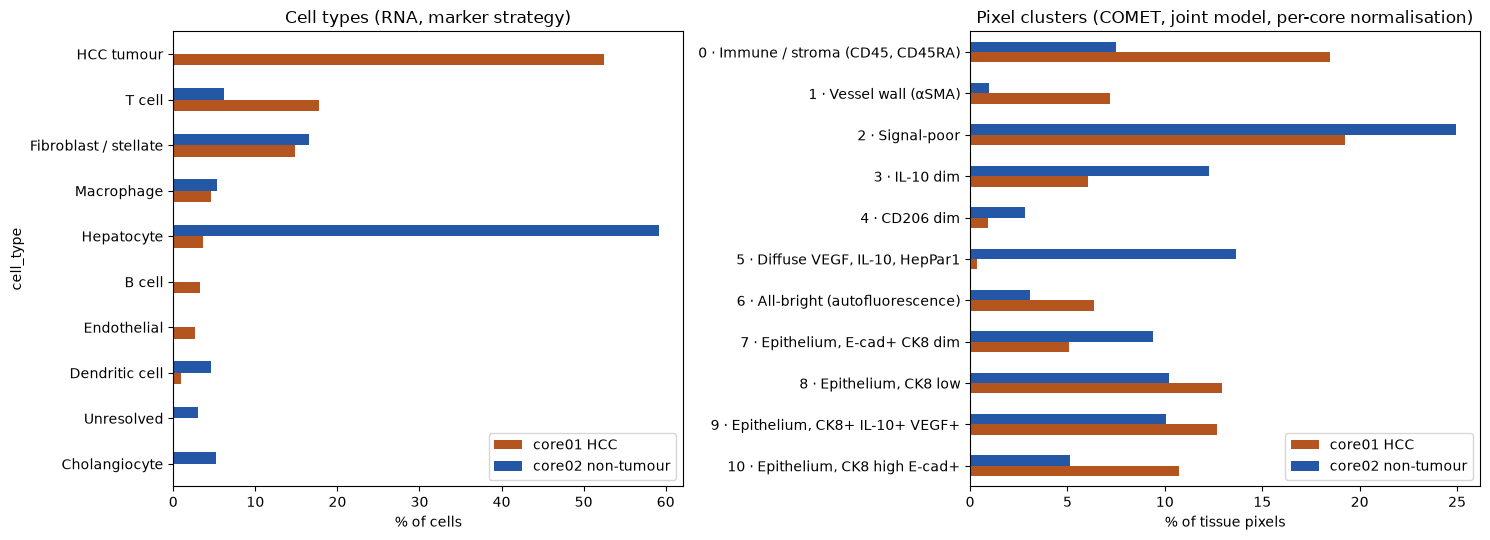

In [27]:
# ── Tumour vs non-tumour: the same comparison from two independent views ────────────────────────────

# Cell tables of the two cores (one row per Xenium cell: RNA cell type, centroid, …)
obs1 = pd.read_csv(PREP / "integration_obs.csv", index_col=0)     # core01, HCC
obs2 = pd.read_csv(C2 / "integration_obs.csv", index_col=0)       # core02, non-tumour liver

# View 1, cell level: share of each RNA cell type in each core (fractions, so cores of different sizes compare).
# A type absent from one core (e.g. HCC tumour in core02) gets 0 rather than NaN.
cells = pd.concat({"core01 HCC": obs1["cell_type"].value_counts(normalize=True),
                   "core02 non-tumour": obs2["cell_type"].value_counts(normalize=True)}, axis=1).fillna(0)

# View 2, pixel level (no segmentation): share of tissue pixels in each spatiomic cluster.
# The maps come from ONE joint model fitted on pixels from both cores, each normalised with its own
# percentiles, so cluster k is the same phenotype in both cores and the shares can be compared directly.
def pix_share(path):
    lab = np.load(path); lab = lab[lab >= 0]                       # drop background (-1)
    return pd.Series(np.bincount(lab, minlength=len(JOINT_CLUSTER_NAMES)) / lab.size,   # pixels per cluster / all tissue pixels
                     index=[f"{k} · {v}" for k, v in JOINT_CLUSTER_NAMES.items()])     # e.g. "1 · Vessel wall (αSMA)"

pixels = pd.concat({"core01 HCC": pix_share(C2 / "joint" / "core01_labelled_ds2.npy"),
                    "core02 non-tumour": pix_share(C2 / "joint" / "core02_labelled_ds2.npy")}, axis=1)

# ── Side by side: % of cells (left) vs % of tissue pixels (right), core01 orange, core02 blue ───────
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))

# Left: cell types, sorted by their share in core01
(cells * 100).sort_values("core01 HCC").plot.barh(ax=axs[0], color=["#B4541F", "#2457A6"]); axs[0].set_xlabel("% of cells")
axs[0].set_title("Cell types (RNA, marker strategy)")

# Right: pixel clusters, in cluster order (reversed so that cluster 0 is at the top)
(pixels * 100).iloc[::-1].plot.barh(ax=axs[1], color=["#B4541F", "#2457A6"]); axs[1].set_xlabel("% of tissue pixels")
axs[1].set_title("Pixel clusters (COMET, joint model, per-core normalisation)"); plt.tight_layout()

**Question.** Which compartments change between tumour and non-tumour liver? Do the RNA-based cell types and the
segmentation-free pixel clusters tell the same story? Where do they disagree, and which would you believe?
One core per condition: this is an illustration, not a test.

<details>
<summary><b>Answer</b> (click to reveal)</summary>

- What changes: non-tumour liver has much less immune tissue (T cells 18% → 6%, immune/stroma pixels 18.5% → 7.5%), no lymphoid aggregate and very little αSMA (7.2% → 1.0%). It’s dominated by hepatocytes (59%) and the diffuse HepPar1 pixel cluster (13.6% vs 0.4%).
- Where the views agree: both show the loss of immune tissue and of the aggregate.
- Where they disagree:
    - Tumour vs normal epithelium: RNA separates them; pixels can’t, because each core was normalised on its own. Trust RNA for identity.
    - Fibroblasts: the share barely changes, but αSMA pixels drop. This adds a cell state rather than contradicting the RNA: quiescent stellate cells in normal liver, activated ones in HCC.
    - Endothelial cells (0% in core02 by RNA): this is a typing failure, since normal liver is full of sinusoids. Trust the images.
- Rule: trust pixels for compartment size and RNA for cell identity. Where they disagree, look at the images. One core per condition, so it’s an illustration, not a test.

</details>